In [267]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [268]:
df=pd.read_csv(r"C:\Users\Owner\Desktop\대학\cct S1\machine learning\CA1\Diabetes Dataset.csv")
#df=pd.read_Csv("Diabetes Dataset.csv")

In [269]:
df.head()

,Gender,Age,Physical Activity,Smoking Status,Alcohol Intake,Glucose,Blood Pressure,Skin Thickness,Insulin,BMI,Cholesterol,Diabetes Pedigree Function,Family History,Hypertension,Outcome
0,Male,63,Moderate,Former,NaN,103,40,7,41,28.196216,167,1.393,Yes,Yes,Diabetic
1,Female,51,Moderate,Never,Regular,104,59,21,51,30.438114,209,0.815,No,No,Diabetic
2,Female,74,Moderate,Current,NaN,128,70,18,199,38.700428,170,0.244,No,No,Diabetic
3,Male,78,Low,Never,Occasional,148,72,15,110,44.861600,170,0.336,No,No,Diabetic
4,Male,32,High,Never,NaN,102,55,18,49,21.591572,211,1.146,Yes,No,Non-diabetic


In [270]:
df.shape

(20000, 15)

In [271]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 20000 entries, 0 to 19999
Data columns (total 15 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   Gender                      20000 non-null  str    
 1   Age                         20000 non-null  int64  
 2   Physical Activity           20000 non-null  str    
 3   Smoking Status              20000 non-null  str    
 4   Alcohol Intake              10075 non-null  str    
 5   Glucose                     20000 non-null  int64  
 6   Blood Pressure              20000 non-null  int64  
 7   Skin Thickness              20000 non-null  int64  
 8   Insulin                     20000 non-null  int64  
 9   BMI                         20000 non-null  float64
 10  Cholesterol                 20000 non-null  int64  
 11  Diabetes Pedigree Function  20000 non-null  float64
 12  Family History              20000 non-null  str    
 13  Hypertension                20000 non-null

In [272]:
df.describe()

,Age,Glucose,Blood Pressure,Skin Thickness,Insulin,BMI,Cholesterol,Diabetes Pedigree Function
count,20000.000000,20000.000000,20000.000000,20000.000000,20000.000000,20000.000000,20000.000000,20000.000000
mean,49.565400,119.603400,69.432850,20.105450,83.952550,32.008980,189.555400,1.310665
std,17.320956,29.590699,12.016115,9.130969,53.026841,6.913271,35.081701,0.693984
min,20.000000,40.000000,30.000000,7.000000,15.000000,15.000000,100.000000,0.100000
25%,35.000000,99.000000,61.000000,13.000000,40.000000,27.314424,166.000000,0.704750
50%,50.000000,120.000000,69.000000,20.000000,79.000000,31.994040,190.000000,1.316000
75%,64.000000,140.000000,78.000000,26.000000,120.000000,36.750196,213.000000,1.914000
max,79.000000,200.000000,114.000000,57.000000,276.000000,50.000000,320.000000,2.500000


In [273]:
df.describe(include='str')

,Gender,Physical Activity,Smoking Status,Alcohol Intake,Family History,Hypertension,Outcome
count,20000,20000,20000,10075,20000,20000,20000
unique,2,3,3,2,2,2,2
top,Male,Moderate,Never,Occasional,No,No,Diabetic
freq,10028,9976,11999,6014,12083,13974,16726


In [274]:
df.isnull().sum()

Gender                           0
Age                              0
Physical Activity                0
Smoking Status                   0
Alcohol Intake                9925
Glucose                          0
Blood Pressure                   0
Skin Thickness                   0
Insulin                          0
BMI                              0
Cholesterol                      0
Diabetes Pedigree Function       0
Family History                   0
Hypertension                     0
Outcome                          0
dtype: int64

In [275]:
df['Alcohol Intake'].unique()
# none 이 nan을으로 인식됨

<StringArray>
[nan, 'Regular', 'Occasional']
Length: 3, dtype: str

In [276]:
df['Alcohol Intake']= df['Alcohol Intake'].fillna('None')

In [277]:
df['Alcohol Intake'].head()

0          None
1       Regular
2          None
3    Occasional
4          None
Name: Alcohol Intake, dtype: str

In [278]:
df['Alcohol Intake'].info()

<class 'pandas.Series'>
RangeIndex: 20000 entries, 0 to 19999
Series name: Alcohol Intake
Non-Null Count  Dtype
--------------  -----
20000 non-null  str  
dtypes: str(1)
memory usage: 156.4 KB


In [279]:
df.isnull().sum()

Gender                        0
Age                           0
Physical Activity             0
Smoking Status                0
Alcohol Intake                0
Glucose                       0
Blood Pressure                0
Skin Thickness                0
Insulin                       0
BMI                           0
Cholesterol                   0
Diabetes Pedigree Function    0
Family History                0
Hypertension                  0
Outcome                       0
dtype: int64

In [280]:
numerical_cols = [
    "Age",
    "Glucose",
    "Blood Pressure",
    "Skin Thickness",
    "Insulin",
    "BMI",
    "Cholesterol",
    "Diabetes Pedigree Function"

]

In [281]:
categorical_cols=[
    "Gender",
    "Physical Activity",
    "Smoking Status",
    "Alcohol Intake",
    "Family History",
    "Hypertension",
    "Outcome"
]

In [282]:
numerical_summary=df[numerical_cols].describe(include='all')
print(numerical_summary)

                Age       Glucose  Blood Pressure  Skin Thickness  \
count  20000.000000  20000.000000    20000.000000    20000.000000   
mean      49.565400    119.603400       69.432850       20.105450   
std       17.320956     29.590699       12.016115        9.130969   
min       20.000000     40.000000       30.000000        7.000000   
25%       35.000000     99.000000       61.000000       13.000000   
50%       50.000000    120.000000       69.000000       20.000000   
75%       64.000000    140.000000       78.000000       26.000000   
max       79.000000    200.000000      114.000000       57.000000   

            Insulin           BMI   Cholesterol  Diabetes Pedigree Function  
count  20000.000000  20000.000000  20000.000000                20000.000000  
mean      83.952550     32.008980    189.555400                    1.310665  
std       53.026841      6.913271     35.081701                    0.693984  
min       15.000000     15.000000    100.000000                   

In [283]:
categorical_summary=df[categorical_cols].astype(str).describe(include='all')
print(categorical_summary)

       Gender Physical Activity Smoking Status Alcohol Intake Family History  \
count   20000             20000          20000          20000          20000   
unique      2                 3              3              3              2   
top      Male          Moderate          Never           None             No   
freq    10028              9976          11999           9925          12083   

       Hypertension   Outcome  
count         20000     20000  
unique            2         2  
top              No  Diabetic  
freq          13974     16726  


In [284]:
import sklearn.preprocessing as preproc

In [285]:
oe=preproc.OrdinalEncoder() # ordinal encoder -> independent variable. 

In [286]:
df['Physical Activity'].unique()


<StringArray>
['Moderate', 'Low', 'High']
Length: 3, dtype: str

In [287]:
df['Physical Activity']=oe.fit_transform(df[['Physical Activity']])

In [288]:
df['Physical Activity'].unique()
#['Moderate', 'Low', 'High' = 2,1,0

array([2., 1., 0.])

In [289]:
df['Smoking Status'].unique()


<StringArray>
['Former', 'Never', 'Current']
Length: 3, dtype: str

In [290]:
df['Smoking Status']=oe.fit_transform(df[['Smoking Status']])

In [291]:
df['Smoking Status'].unique()


array([1., 2., 0.])

In [292]:
df['Alcohol Intake'].unique()

<StringArray>
['None', 'Regular', 'Occasional']
Length: 3, dtype: str

In [293]:
df['Alcohol Intake']=oe.fit_transform(df[['Alcohol Intake']])

In [294]:
df['Alcohol Intake'].unique()

array([0., 2., 1.])

In [295]:
df['Gender'].unique()

<StringArray>
['Male', 'Female']
Length: 2, dtype: str

In [296]:
df=pd.get_dummies(df, columns=['Gender'], dtype=int)

In [297]:
df['Family History'].unique()

<StringArray>
['Yes', 'No']
Length: 2, dtype: str

In [298]:
df=pd.get_dummies(df,columns=['Family History'], dtype=int)

In [299]:
df['Hypertension'].unique()

<StringArray>
['Yes', 'No']
Length: 2, dtype: str

In [300]:
df=pd.get_dummies(df,columns=['Hypertension'], dtype=int)

In [301]:
df['Outcome'].unique()

<StringArray>
['Diabetic', 'Non-diabetic']
Length: 2, dtype: str

In [302]:
#to incode it  ( label encoder -> target variable)
le = preproc.LabelEncoder()

In [303]:
df['Outcome']=le.fit_transform(df['Outcome'])

In [304]:
df['Outcome'].unique()

array([0, 1])

In [305]:
df.head()

,Age,Physical Activity,Smoking Status,Alcohol Intake,Glucose,Blood Pressure,Skin Thickness,Insulin,BMI,Cholesterol,Diabetes Pedigree Function,Outcome,Gender_Female,Gender_Male,Family History_No,Family History_Yes,Hypertension_No,Hypertension_Yes
0,63,2.0,1.0,0.0,103,40,7,41,28.196216,167,1.393,0,0,1,0,1,0,1
1,51,2.0,2.0,2.0,104,59,21,51,30.438114,209,0.815,0,1,0,1,0,1,0
2,74,2.0,0.0,0.0,128,70,18,199,38.700428,170,0.244,0,1,0,1,0,1,0
3,78,1.0,2.0,1.0,148,72,15,110,44.861600,170,0.336,0,0,1,1,0,1,0
4,32,0.0,2.0,0.0,102,55,18,49,21.591572,211,1.146,1,0,1,0,1,1,0


In [310]:
df.shape

(20000, 18)

In [311]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 20000 entries, 0 to 19999
Data columns (total 18 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   Age                         20000 non-null  int64  
 1   Physical Activity           20000 non-null  float64
 2   Smoking Status              20000 non-null  float64
 3   Alcohol Intake              20000 non-null  float64
 4   Glucose                     20000 non-null  int64  
 5   Blood Pressure              20000 non-null  int64  
 6   Skin Thickness              20000 non-null  int64  
 7   Insulin                     20000 non-null  int64  
 8   BMI                         20000 non-null  float64
 9   Cholesterol                 20000 non-null  int64  
 10  Diabetes Pedigree Function  20000 non-null  float64
 11  Outcome                     20000 non-null  int64  
 12  Gender_Female               20000 non-null  int64  
 13  Gender_Male                 20000 non-null

"In this study, the target variable 'Outcome' was encoded as binary classes, where 'Non-diabetic' is represented by 0 and 'Diabetic' is represented by 1."

<Axes: xlabel='Outcome', ylabel='Count'>

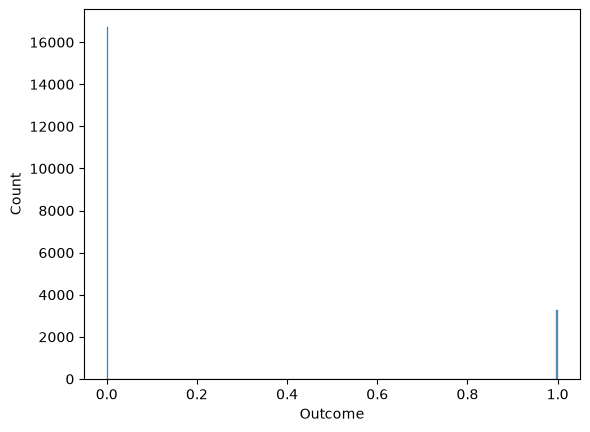

In [316]:
sns.histplot(data=df,x='Outcome')

C:\Users\Owner\AppData\Local\Temp\ipykernel_30812\3326169707.py:1: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=df, y='Blood Pressure', x='Outcome', palette='Set1')


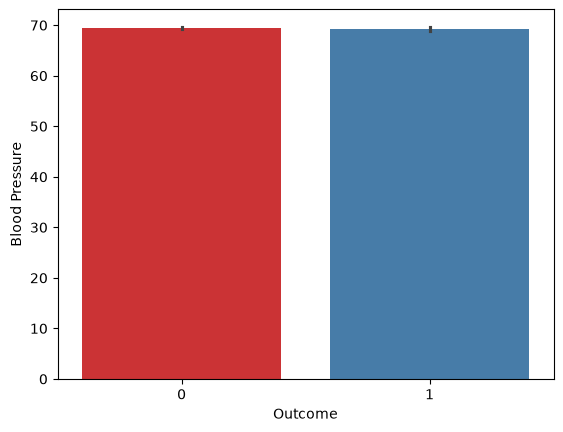

In [314]:
sns.barplot(data=df, y='Blood Pressure', x='Outcome', palette='Set1')
plt.show()

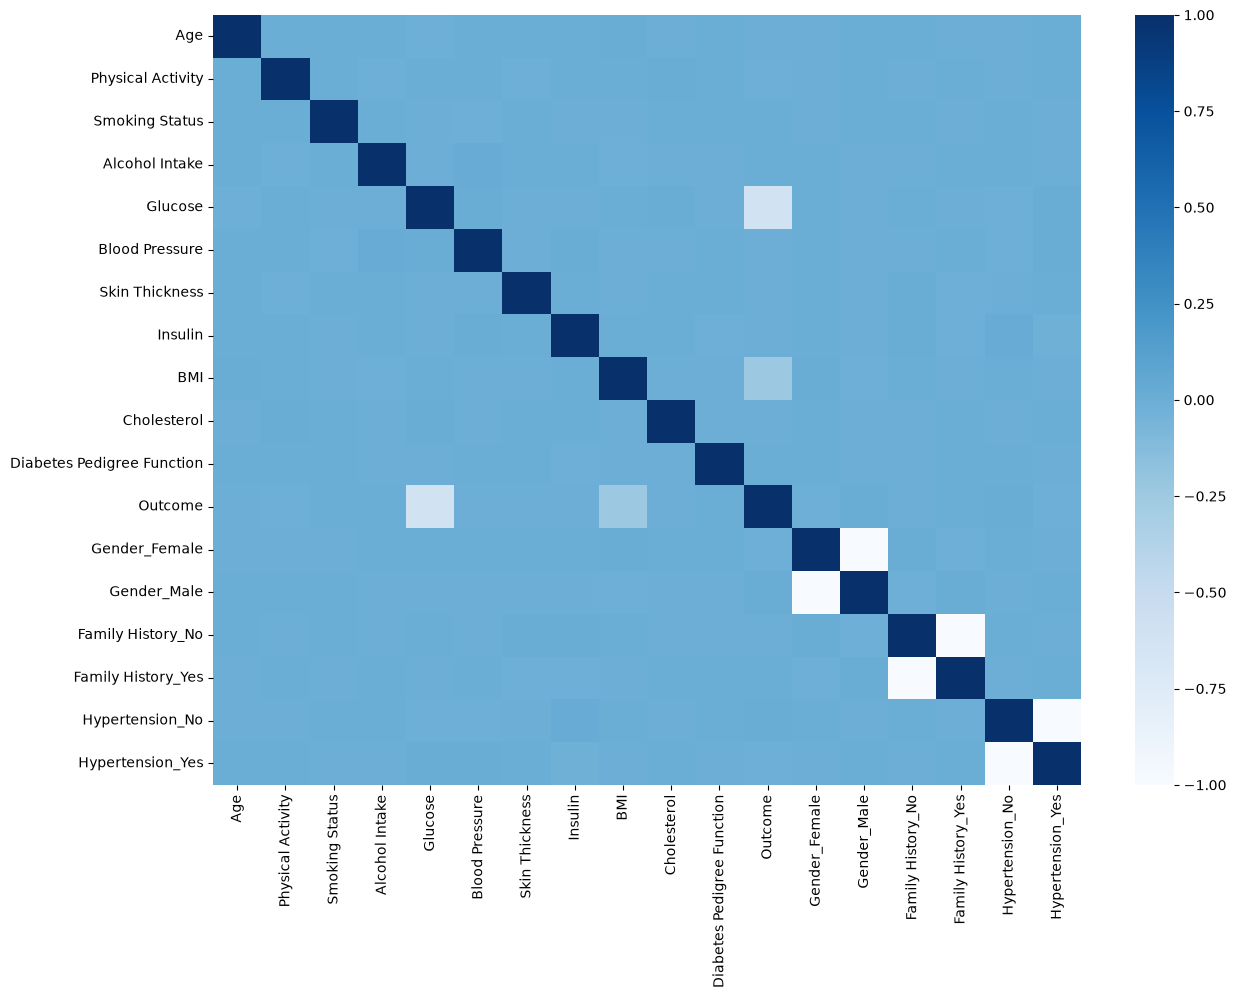

In [309]:
plt.figure(figsize=(14, 10))

corr = df.select_dtypes(include='number').corr()

sns.heatmap(
    corr,
    annot=False,
    cmap='Blues', 
)
plt.show()